# FinScope Rwanda 2024 — Non-Health Insurance Uptake: Data Prep, Modeling & SHAP

**NISR Big Data Hackathon 2026, Track 2 (Financial Inclusion & Poverty Reduction)**

*Revised notebook — adds Section 11 (SHAP feature importance) on top of the model-comparison
checkpoint. The earlier `prepare_insurance_target_dataset.ipynb` is left untouched; this is a
separate file.*

Builds three binary targets from FinScope Rwanda 2024 microdata:

| Target | Definition |
|---|---|
| `any_uptake` | holds **any** of the 16 products (the headline 28.6% figure) |
| `insurance_uptake` | holds any of the 13 general insurance products (`i6_01`–`i6_12`, `i6_16`) |
| `pension_uptake` | holds any of the 3 pension / long-term savings products (RSSB, private pension, Ejo Heza) |

It audits missingness across the full predictor candidate pool, cleans a **30-variable**
predictor set (the original 15 + 10 extra + 5 credit/borrowing variables), runs a short EDA, writes one
stratified 70/30 split shared by all three targets, and compares logistic regression,
random forest and XGBoost for each target on three nested feature sets: base 15, + 10 extras, + 5 credit.

**Input:** `FinScope 2024 Rwanda.dta` (same folder as this notebook)

**Output:** `finscope_train_raw.csv` / `finscope_test_raw.csv` (readable categories) and
`finscope_train_processed.csv` / `finscope_test_processed.csv` (one-hot encoded, model-ready).

**Stopping point for this pass:** model comparison (Section 10) plus SHAP feature importance
(Section 11). Hyperparameter tuning, personas and the dashboard are built separately (the
Streamlit app in `streamlit_app/` reuses the modeling choices made here).

**Kernel:** XGBoost needs a working OpenMP runtime, which on this Mac only exists in the `base`
conda environment — run this notebook with the **"Python (finscope-base)"** kernel.

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

RAW_FILE = "FinScope 2024 Rwanda.dta"
RANDOM_STATE = 42
TEST_SIZE = 0.30

## Section 1 — Load

Only the columns we need — the raw `.dta` has 2,442 columns.

**Target components:** `i6_01`–`i6_16` ("Do you have any of the following insurance products?")
are asked of **all** 13,994 respondents with zero missingness. The alternative pair
`qf1_07`/`qf4_07` follows a skip pattern (`qf4` is only asked of the ~1–2% who say "yes" to
`qf1`), so it was ruled out.

**Predictors:** the original 15 (`BASE_FEATURES`) plus 10 extra variables (`EXTRA_FEATURES`) that
were fully complete but left out of the first pass (food insecurity, housing situation, household size,
the remaining insurance attitude / awareness questions), plus 5 credit / borrowing variables
(`CREDIT_FEATURES`) from the FinScope credit module (`h2`/`h3`).

*Caveat on the credit items:* bank loans often come bundled with credit-life insurance (`i6_05`), and
bank / SACCO borrowers are disproportionately salaried people who already have RSSB pension, so part
of their signal is mechanical. `borrowed_past_12m` is not tied to any one product and is the safest of
the five.

*Caveat on the awareness items:* people who already hold a product may be more likely to say they
are aware of it, so part of that signal can be reverse causation. They are kept (the plan lists
awareness / trust as a predictor category) but worth keeping in mind when interpreting results.

In [2]:
PENSION_COLS = ["i6_13", "i6_14", "i6_15"]                     # RSSB, private pension, Ejo Heza
TARGET_COLS = [f"i6_{i:02d}" for i in range(1, 17)]
INSURANCE_COLS = [c for c in TARGET_COLS if c not in PENSION_COLS]

# Original 15 predictors. Raw FinScope code -> readable name.
BASE_FEATURES = {
    # Demographic
    "b1": "age", "b2": "sex", "b3": "marital_status", "c4a": "education",
    # Socioeconomic
    "c13a": "ubudehe_category", "c12_16": "owns_motor_vehicle",
    "n1b": "main_livelihood",              # recoded to 6 broad groups, see Section 4
    # Geographic access
    "a6": "urban_rural", "d1b10": "time_to_bank",
    "d1a15": "time_to_insurance_branch",   # NOTE: for item 15 the a/b suffixes are swapped vs. every
                                            # other d1 pair - d1a15 holds the TIME categories, d1b15
                                            # holds DISTANCE. Verified against the value labels.
    "d1b7": "time_to_sacco",
    # Financial behaviour
    "qf1_05": "used_mobile_money", "e2c": "saves_money", "e9b": "has_emergency_savings",
    "i3_3": "aware_microinsurance",
}

# 10 extra predictors, all with zero missingness (see Section 2).
EXTRA_FEATURES = {
    "c5_1": "skipped_meal_frequency",           # food insecurity
    "c7a": "housing_situation",
    "hh_size": "household_size",
    "i1_1": "agrees_insurance_never_pays",
    "i1_2": "agrees_insurance_protects",
    "i1_3": "agrees_savings_better",
    "i1_4": "understands_insurance",
    "i3_1": "aware_medical_insurance",
    "i3_2": "aware_life_insurance",
    "i3_4": "aware_third_party_insurance",
}

# 5 credit / borrowing predictors, all with zero missingness (FinScope credit module).
CREDIT_FEATURES = {
    "h2_1": "borrowed_past_12m",
    "h3_01": "borrowed_from_bank",
    "h3_06": "borrowed_from_umurenge_sacco",
    "h3_03": "borrowed_from_mfi_or_other_sacco",
    "h3_05": "borrowed_via_mobile_money",
}

ALL_FEATURES_MAP = {**BASE_FEATURES, **EXTRA_FEATURES, **CREDIT_FEATURES}

# Kept for identification / EDA / weighting - NOT used as model features.
CONTEXT_COLS = ["key", "a1", "pop_wt"]

usecols = list(dict.fromkeys(CONTEXT_COLS + list(ALL_FEATURES_MAP) + TARGET_COLS))
df = pd.read_stata(RAW_FILE, columns=usecols, convert_categoricals=True)
print(f"Loaded {df.shape[0]:,} respondents x {df.shape[1]} columns")
df.head()

Loaded 13,994 respondents x 49 columns


,key,a1,pop_wt,b1,b2,b3,c4a,c13a,c12_16,n1b,a6,d1b10,d1a15,d1b7,qf1_05,e2c,e9b,i3_3,c5_1,c7a,...,h3_01,h3_06,h3_03,h3_05,i6_01,i6_02,i6_03,i6_04,i6_05,i6_06,i6_07,i6_08,i6_09,i6_10,i6_11,i6_12,i6_13,i6_14,i6_15,i6_16
0,11838,East,1168.281635,60,Male,Married,Primary 4-6,2nd category,No,Salary/wages from Government institution,Rural,More than 60 minutes,Between 31 and 60 minutes,More than 60 minutes,No,Sometimes,No,Yes,Never,You/your household rent this dwelling.,...,Yes,No,No,No,No,No,No,Yes,No,No,No,No,No,No,No,No,Yes,Yes,No,No
1,12132,East,331.291150,55,Male,Divorced/Separated,Primary 1-3,3rd category,No,Rental income,Rural,Between 15 and 30 minutes,Less than 15 minutes,Less than 15 minutes,Yes,Do not save,No,No,Never,You own this dwelling,...,No,Yes,No,No,No,No,Yes,No,No,No,No,No,No,No,Yes,No,No,No,No,No
2,1328,Kigali,283.327154,33,Male,Married,Secondary 4-6,2nd category,No,Salary/wages from a private business/company,Urban,Between 15 and 30 minutes,Between 15 and 30 minutes,Between 31 and 60 minutes,No,Do not save,No,No,Never,You own this dwelling,...,Yes,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No
3,11377,East,656.777371,76,Male,Married,Secondary 4-6,3rd category,Yes,Money from farming,Rural,Between 31 and 60 minutes,Between 31 and 60 minutes,Between 15 and 30 minutes,Yes,Always,Yes,Yes,Never,You own this dwelling,...,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,No
4,10659,East,757.121752,53,Female,Living together,Primary 4-6,3rd category,No,Salary/wages from Government institution,Rural,Don?t know,Don?t know,Between 31 and 60 minutes,No,Always,Yes,No,A few times,You own this dwelling,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,No,No,No,No,No,No


## Section 2 — Missingness audit on the full predictor candidate shortlist

This is the evidence behind the column selection: every candidate variable from the Variable
Guide's "Predictor Shortlist" sheet plus the credit / borrowing questions (~83 columns), loaded fresh
from the raw data and checked for `%` missing — not asserted from memory.

Anything crossing **25% missing** is flagged `Dropped (heavy missingness)` and excluded. Three
more exclusions can't be seen from missingness alone: `qf4_05`/`qf4_10` follow a skip pattern,
and `i7` ("main reason for not having insurance") is only asked of people *without* insurance,
so it is circular with the target regardless of its missingness rate.

In [3]:
# Raw code -> category, matching the Variable Guide's own section groupings.
CANDIDATE_FEATURES = {
    # Demographics
    "a1": "Demographic", "a2": "Demographic", "a6": "Demographic", "b1": "Demographic",
    "b2": "Demographic", "b3": "Demographic", "c1c": "Demographic", "c4a": "Demographic",
    "c4b": "Demographic", "c4c": "Demographic", "c4d": "Demographic", "hh_size": "Demographic",
    "hh_head": "Demographic", "bo": "Demographic",
    # Socioeconomic / poverty / assets
    "c13a": "Socioeconomic", "c13d": "Socioeconomic", "c5_1": "Socioeconomic",
    "c5_4": "Socioeconomic", "c7a": "Socioeconomic", "c8b": "Socioeconomic",
    "c9": "Socioeconomic", "c11a": "Socioeconomic", "c12_16": "Socioeconomic",
    "c14_2": "Socioeconomic", "c14_4": "Socioeconomic", "c14_6": "Socioeconomic",
    "n1b": "Socioeconomic", "n11": "Socioeconomic", "n12": "Socioeconomic",
    # Geographic access
    "d1a10": "Geographic access", "d1b10": "Geographic access", "d1a11": "Geographic access",
    "d1b11": "Geographic access", "d1a14": "Geographic access", "d1b14": "Geographic access",
    "d1a15": "Geographic access", "d1b15": "Geographic access", "d1a7": "Geographic access",
    "d1b7": "Geographic access", "d1a8": "Geographic access",
    # Financial behaviour: savings & credit
    "e2c": "Financial behaviour", "e7": "Financial behaviour", "e9b": "Financial behaviour",
    "e10a2": "Financial behaviour", "e10a3": "Financial behaviour", "g1": "Financial behaviour",
    "qf1_10": "Financial behaviour", "qf4_10": "Financial behaviour", "h1": "Financial behaviour",
    # Financial behaviour: digital / mobile money
    "qf1_05": "Financial behaviour", "qf4_05": "Financial behaviour", "f4d_1": "Financial behaviour",
    "f4e": "Financial behaviour", "c14_5": "Financial behaviour",
    # Financial behaviour: insurance/pension awareness & attitudes
    "i1_1": "Financial behaviour", "i1_2": "Financial behaviour", "i1_3": "Financial behaviour",
    "i1_4": "Financial behaviour", "i3_1": "Financial behaviour", "i3_2": "Financial behaviour",
    "i3_3": "Financial behaviour", "i3_4": "Financial behaviour", "i7": "Financial behaviour",
    "i10_2": "Financial behaviour", "i9a": "Financial behaviour", "n1a_9": "Financial behaviour",
    "n1a_10": "Financial behaviour",
    # Financial behaviour: credit / borrowing module
    "h2_1": "Financial behaviour", "h3_01": "Financial behaviour", "h3_02": "Financial behaviour",
    "h3_03": "Financial behaviour", "h3_04": "Financial behaviour", "h3_05": "Financial behaviour",
    "h3_06": "Financial behaviour", "h3_07": "Financial behaviour", "h3_08": "Financial behaviour",
    # Shocks / vulnerability (context only)
    "i2_2": "Shocks/vulnerability", "i2_6": "Shocks/vulnerability", "i2_7": "Shocks/vulnerability",
    "i2_8": "Shocks/vulnerability", "i2_15": "Shocks/vulnerability", "cc1": "Shocks/vulnerability",
}

MISSINGNESS_THRESHOLD = 25.0  # percent

cand_df = pd.read_stata(RAW_FILE, columns=list(CANDIDATE_FEATURES.keys()), convert_categoricals=False)
pct_missing = cand_df.isna().mean().mul(100).round(1)

missing_audit = pd.DataFrame({
    "variable": pct_missing.index,
    "category": [CANDIDATE_FEATURES[c] for c in pct_missing.index],
    "pct_missing": pct_missing.values,
})

# Known exclusions that missingness alone doesn't explain (skip pattern / circularity).
OTHER_EXCLUSION_NOTE = {
    "qf4_05": "skip pattern (only asked if qf1_05 = yes)",
    "qf4_10": "skip pattern (only asked if qf1_10 = yes)",
    "i7": "only asked of respondents WITHOUT insurance - circular w.r.t. target",
}

def decide(row):
    if row["variable"] in BASE_FEATURES:
        return "Kept - base 15"
    if row["variable"] in EXTRA_FEATURES:
        return "Kept - extra 10"
    if row["variable"] in CREDIT_FEATURES:
        return "Kept - credit 5"
    if row["variable"] in OTHER_EXCLUSION_NOTE:
        return OTHER_EXCLUSION_NOTE[row["variable"]]
    if row["pct_missing"] >= MISSINGNESS_THRESHOLD:
        return "Dropped (heavy missingness)"
    return "Complete but not selected"

missing_audit["decision"] = missing_audit.apply(decide, axis=1)
missing_audit = missing_audit.sort_values("pct_missing", ascending=False).reset_index(drop=True)
pd.set_option("display.max_rows", len(missing_audit))
missing_audit

,variable,category,pct_missing,decision
0,h1,Financial behaviour,100.0,Dropped (heavy missingness)
1,c14_4,Socioeconomic,91.8,Dropped (heavy missingness)
2,c14_6,Socioeconomic,84.9,Dropped (heavy missingness)
3,f4e,Financial behaviour,79.9,Dropped (heavy missingness)
4,n11,Socioeconomic,72.2,Dropped (heavy missingness)
5,n12,Socioeconomic,69.1,Dropped (heavy missingness)
6,qf4_05,Financial behaviour,64.9,skip pattern (only asked if qf1_05 = yes)
7,c1c,Demographic,56.6,Dropped (heavy missingness)
8,qf4_10,Financial behaviour,49.8,skip pattern (only asked if qf1_10 = yes)
9,c8b,Socioeconomic,31.2,Dropped (heavy missingness)


In [4]:
# Just the variables that crossed the missingness threshold - the exact evidence for the
# "excluded for heavy missingness" calls above.
missing_audit[missing_audit["pct_missing"] >= MISSINGNESS_THRESHOLD]

,variable,category,pct_missing,decision
0,h1,Financial behaviour,100.0,Dropped (heavy missingness)
1,c14_4,Socioeconomic,91.8,Dropped (heavy missingness)
2,c14_6,Socioeconomic,84.9,Dropped (heavy missingness)
3,f4e,Financial behaviour,79.9,Dropped (heavy missingness)
4,n11,Socioeconomic,72.2,Dropped (heavy missingness)
5,n12,Socioeconomic,69.1,Dropped (heavy missingness)
6,qf4_05,Financial behaviour,64.9,skip pattern (only asked if qf1_05 = yes)
7,c1c,Demographic,56.6,Dropped (heavy missingness)
8,qf4_10,Financial behaviour,49.8,skip pattern (only asked if qf1_10 = yes)
9,c8b,Socioeconomic,31.2,Dropped (heavy missingness)


## Section 3 — Build the three targets

All 16 `i6_*` columns are Yes/No with zero missingness (asked of the full sample).

- `any_uptake` — any of the 16 products (matches the 28.6% headline figure)
- `insurance_uptake` — any of the 13 general insurance products
- `pension_uptake` — any of RSSB public pension, private pension, Ejo Heza

Insurance and pension are modelled separately because their drivers differ: pension uptake follows
formal employment and a heavily promoted government scheme (Ejo Heza), while insurance uptake
follows awareness, affordability and trust. About 6% of respondents hold both.

In [5]:
df["any_uptake"] = (df[TARGET_COLS] == "Yes").any(axis=1).astype(int)
df["insurance_uptake"] = (df[INSURANCE_COLS] == "Yes").any(axis=1).astype(int)
df["pension_uptake"] = (df[PENSION_COLS] == "Yes").any(axis=1).astype(int)
df = df.drop(columns=TARGET_COLS)

TARGETS = ["any_uptake", "insurance_uptake", "pension_uptake"]

prevalence = pd.DataFrame({
    "unweighted": [df[t].mean() for t in TARGETS],
    "weighted (pop_wt)": [np.average(df[t], weights=df["pop_wt"]) for t in TARGETS],
}, index=TARGETS)
print("Target prevalence (any_uptake weighted should match the project's headline 28.6%):")
prevalence.map("{:.1%}".format)

Target prevalence (any_uptake weighted should match the project's headline 28.6%):


,unweighted,weighted (pop_wt)
any_uptake,30.7%,28.6%
insurance_uptake,13.5%,12.6%
pension_uptake,23.4%,21.5%


## Section 4 — Clean & recode predictors

- Cosmetic fix for a mis-encoded apostrophe in some Stata value labels ("Don?t know").
- **`main_livelihood` (`n1b`): 23 raw categories → 6 groups.** Two raw categories — `'Private
  pension'` and `'Government pension'` — mean the respondent's main livelihood *is* a pension, so
  they almost certainly already hold `i6_13`/`i6_14`. Kept separate they would leak the target into a
  predictor, so they are folded into the broad "Dependent/social transfer" bucket (~2,250 people),
  which dilutes that leakage to a tolerable residual.
- `housing_situation` (`c7a`): long survey labels shortened to 7 readable categories.
- Across all 30 predictors there is exactly **one** missing value (`time_to_insurance_branch`),
  filled with `"Don't know"`.

In [6]:
df = df.rename(columns=ALL_FEATURES_MAP)

for col in df.select_dtypes(include="category").columns:
    df[col] = df[col].cat.rename_categories(
        lambda x: x.replace("Don?t know", "Don't know") if isinstance(x, str) else x
    )

LIVELIHOOD_GROUPS = {
    "Salaried": [
        "Salary/wages from Government institution", "Salary/wages from a private business/company",
        "Salary/wages from a farmer", "Salary/wages from an individual",
    ],
    "Self-employed": ["Self-employed (registered/licensed)", "Self-employed (not registered/licensed)"],
    "Farming/fishing": [
        "Money from farming", "Money from fishing",
        "Sell something I grow", "Sell something I collect from nature",
    ],
    "Informal/piece work": ["Piece work", "Make goods to sell"],
    "Rental/asset income": ["Rental income"],
    "Dependent/social transfer": [
        "Private pension", "Government pension", "Government", "Social protection",
        "Gift", "Remittances", "Get money from household member",
        "Household member pays my expenses", "VUP public works", "Humanitarian",
    ],
}
livelihood_lookup = {raw: group for group, raws in LIVELIHOOD_GROUPS.items() for raw in raws}
df["main_livelihood"] = df["main_livelihood"].astype(str).str.strip().map(livelihood_lookup)

HOUSING_MAP = {
    "You own this dwelling": "Own",
    "You own this dwelling together with someone else": "Own jointly",
    "You/your household rent this dwelling.": "Rent",
    "A member/other member of the household (not you) own this dwelling.": "Household member owns",
    "The dwelling is provided to you/your household rent free.": "Rent free",
    "Other (specify)": "Other",
    "Does not know": "Don't know",
}
df["housing_situation"] = df["housing_situation"].astype(str).str.strip().map(HOUSING_MAP)

assert df["main_livelihood"].notna().all() and df["housing_situation"].notna().all(), "unmapped category"

ALL_NAMES = list(ALL_FEATURES_MAP.values())
BASE_NAMES = list(BASE_FEATURES.values())
EXTRA_NAMES = list(EXTRA_FEATURES.values())
CREDIT_NAMES = list(CREDIT_FEATURES.values())
NUMERIC_FEATURES = ["age", "household_size"]
CATEGORICAL_FEATURES = [c for c in ALL_NAMES if c not in NUMERIC_FEATURES]

missing_before = df[ALL_NAMES].isna().sum()
print("Missing values across the 30 predictors (before fill):")
print(missing_before[missing_before > 0])

df["time_to_insurance_branch"] = df["time_to_insurance_branch"].astype(str).replace("nan", "Don't know")
df.head()

Missing values across the 30 predictors (before fill):
time_to_insurance_branch    1
dtype: int64


,key,a1,pop_wt,age,sex,marital_status,education,ubudehe_category,owns_motor_vehicle,main_livelihood,urban_rural,time_to_bank,time_to_insurance_branch,time_to_sacco,used_mobile_money,saves_money,has_emergency_savings,aware_microinsurance,skipped_meal_frequency,housing_situation,household_size,agrees_insurance_never_pays,agrees_insurance_protects,agrees_savings_better,understands_insurance,aware_medical_insurance,aware_life_insurance,aware_third_party_insurance,borrowed_past_12m,borrowed_from_bank,borrowed_from_umurenge_sacco,borrowed_from_mfi_or_other_sacco,borrowed_via_mobile_money,any_uptake,insurance_uptake,pension_uptake
0,11838,East,1168.281635,60,Male,Married,Primary 4-6,2nd category,No,Salaried,Rural,More than 60 minutes,Between 31 and 60 minutes,More than 60 minutes,No,Sometimes,No,Yes,Never,Rent,5,Disagree,Agree,Agree,Agree,Yes,Yes,No,Yes,Yes,No,No,No,1,1,1
1,12132,East,331.291150,55,Male,Divorced/Separated,Primary 1-3,3rd category,No,Rental/asset income,Rural,Between 15 and 30 minutes,Less than 15 minutes,Less than 15 minutes,Yes,Do not save,No,No,Never,Own,5,Disagree,Agree,Disagree,Disagree,Yes,Yes,No,Yes,No,Yes,No,No,1,1,0
2,1328,Kigali,283.327154,33,Male,Married,Secondary 4-6,2nd category,No,Salaried,Urban,Between 15 and 30 minutes,Between 15 and 30 minutes,Between 31 and 60 minutes,No,Do not save,No,No,Never,Own,4,Disagree,Agree,Disagree,Disagree,Yes,No,No,Yes,Yes,No,No,No,0,0,0
3,11377,East,656.777371,76,Male,Married,Secondary 4-6,3rd category,Yes,Farming/fishing,Rural,Between 31 and 60 minutes,Between 31 and 60 minutes,Between 15 and 30 minutes,Yes,Always,Yes,Yes,Never,Own,1,Disagree,Agree,Disagree,Agree,Yes,Yes,No,No,No,No,No,No,1,1,1
4,10659,East,757.121752,53,Female,Living together,Primary 4-6,3rd category,No,Salaried,Rural,Don't know,Don't know,Between 31 and 60 minutes,No,Always,Yes,No,A few times,Own,5,Do not know,Do not know,Do not know,Do not know,No,No,No,No,No,No,No,No,1,1,0


## Section 5 — EDA

Weighted (`pop_wt`) uptake by subgroup for all three targets, class balance, and a quick
association check.

In [7]:
def weighted_prevalence_by(frame, group_col):
    w = frame["pop_wt"]
    grp = frame[group_col]
    out = pd.DataFrame({"n": frame.groupby(group_col, observed=True).size()})
    for t in TARGETS:
        out[t] = (frame[t] * w).groupby(grp, observed=True).sum() / w.groupby(grp, observed=True).sum()
    out = out.sort_values("any_uptake", ascending=False)
    out[TARGETS] = out[TARGETS].map("{:.1%}".format)
    return out

for group_col, label in [
    ("a1", "Province"),
    ("urban_rural", "Urban / Rural"),
    ("ubudehe_category", "Ubudehe category"),
    ("education", "Education level"),
]:
    print(f"-- By {label} --")
    display(weighted_prevalence_by(df, group_col))

-- By Province --


,n,any_uptake,insurance_uptake,pension_uptake
a1,,,,
Kigali,1903,32.5%,16.0%,24.7%
North,2174,31.3%,11.7%,25.0%
East,3375,31.1%,14.7%,22.3%
West,3023,25.3%,9.4%,20.6%
South,3519,24.1%,11.4%,16.9%


-- By Urban / Rural --


,n,any_uptake,insurance_uptake,pension_uptake
urban_rural,,,,
Urban,5789,31.0%,14.9%,23.4%
Rural,8205,27.5%,11.6%,20.7%


-- By Ubudehe category --


,n,any_uptake,insurance_uptake,pension_uptake
ubudehe_category,,,,
4th category,38,71.9%,67.7%,47.2%
3rd category,5880,31.4%,16.2%,23.4%
Don't know,172,27.9%,10.3%,24.2%
1st category,1372,27.4%,6.0%,23.5%
Appellxed,56,26.5%,15.4%,16.3%
2nd category,6476,26.2%,10.4%,19.4%


-- By Education level --


,n,any_uptake,insurance_uptake,pension_uptake
education,,,,
University or other higher education,799,63.8%,46.6%,49.4%
Secondary 4-6,1596,34.1%,14.5%,26.0%
Primary 1-3,1875,26.8%,11.3%,18.8%
Primary 4-6,5675,26.1%,10.3%,19.8%
No formal education,2510,24.1%,8.0%,18.3%
Secondary 1-3,1395,23.9%,10.3%,17.8%
Vocational training,144,16.0%,9.3%,9.1%


In [8]:
# Class balance (unweighted share of positives)
print((df[TARGETS].mean() * 100).round(1).astype(str) + "% positive")
print("-> All three are imbalanced (pension ~3:1, insurance ~6:1). Stratified split used below;")
print("   judge models on AUC-ROC / PR-AUC / precision / recall, not plain accuracy.")

any_uptake          30.7% positive
insurance_uptake    13.5% positive
pension_uptake      23.4% positive
dtype: object
-> All three are imbalanced (pension ~3:1, insurance ~6:1). Stratified split used below;
   judge models on AUC-ROC / PR-AUC / precision / recall, not plain accuracy.


In [9]:
# Quick association with each target.
print("Correlation of numeric predictors with each target:")
display(df[NUMERIC_FEATURES + TARGETS].corr().loc[NUMERIC_FEATURES, TARGETS].round(3))

# "Spread" = highest minus lowest uptake rate across a variable's categories. Large spreads can
# come from tiny categories (e.g. Ubudehe '4th category' has only 38 people), so read with care.
spread = {t: {} for t in TARGETS}
for t in TARGETS:
    for col in CATEGORICAL_FEATURES:
        rates = df.groupby(col, observed=True)[t].mean()
        spread[t][col] = rates.max() - rates.min()
print("Spread of uptake rate across categories (categorical predictors):")
pd.DataFrame(spread).sort_values("any_uptake", ascending=False).map("{:.1%}".format)

Correlation of numeric predictors with each target:


,any_uptake,insurance_uptake,pension_uptake
age,0.048,0.002,0.055
household_size,0.041,0.028,0.039


Spread of uptake rate across categories (categorical predictors):


,any_uptake,insurance_uptake,pension_uptake
ubudehe_category,54.9%,59.1%,42.8%
education,47.8%,39.7%,39.5%
owns_motor_vehicle,43.7%,49.9%,24.3%
borrowed_from_bank,36.8%,32.6%,29.3%
borrowed_from_mfi_or_other_sacco,36.7%,24.7%,31.6%
saves_money,25.8%,14.9%,21.3%
borrowed_from_umurenge_sacco,25.6%,8.5%,25.5%
main_livelihood,25.5%,17.7%,22.0%
aware_third_party_insurance,24.9%,18.6%,21.7%
time_to_bank,24.0%,21.1%,16.0%


## Section 6 — Finalize the modeling table

In [10]:
model_df = df[["key"] + TARGETS + ALL_NAMES].copy()
model_df[CATEGORICAL_FEATURES] = model_df[CATEGORICAL_FEATURES].astype(str)
print(f"{model_df.shape[0]:,} rows | 3 targets | {len(BASE_NAMES)} base + {len(EXTRA_NAMES)} extra + {len(CREDIT_NAMES)} credit predictors")
model_df.head()

13,994 rows | 3 targets | 15 base + 10 extra + 5 credit predictors


,key,any_uptake,insurance_uptake,pension_uptake,age,sex,marital_status,education,ubudehe_category,owns_motor_vehicle,main_livelihood,urban_rural,time_to_bank,time_to_insurance_branch,time_to_sacco,used_mobile_money,saves_money,has_emergency_savings,aware_microinsurance,skipped_meal_frequency,housing_situation,household_size,agrees_insurance_never_pays,agrees_insurance_protects,agrees_savings_better,understands_insurance,aware_medical_insurance,aware_life_insurance,aware_third_party_insurance,borrowed_past_12m,borrowed_from_bank,borrowed_from_umurenge_sacco,borrowed_from_mfi_or_other_sacco,borrowed_via_mobile_money
0,11838,1,1,1,60,Male,Married,Primary 4-6,2nd category,No,Salaried,Rural,More than 60 minutes,Between 31 and 60 minutes,More than 60 minutes,No,Sometimes,No,Yes,Never,Rent,5,Disagree,Agree,Agree,Agree,Yes,Yes,No,Yes,Yes,No,No,No
1,12132,1,1,0,55,Male,Divorced/Separated,Primary 1-3,3rd category,No,Rental/asset income,Rural,Between 15 and 30 minutes,Less than 15 minutes,Less than 15 minutes,Yes,Do not save,No,No,Never,Own,5,Disagree,Agree,Disagree,Disagree,Yes,Yes,No,Yes,No,Yes,No,No
2,1328,0,0,0,33,Male,Married,Secondary 4-6,2nd category,No,Salaried,Urban,Between 15 and 30 minutes,Between 15 and 30 minutes,Between 31 and 60 minutes,No,Do not save,No,No,Never,Own,4,Disagree,Agree,Disagree,Disagree,Yes,No,No,Yes,Yes,No,No,No
3,11377,1,1,1,76,Male,Married,Secondary 4-6,3rd category,Yes,Farming/fishing,Rural,Between 31 and 60 minutes,Between 31 and 60 minutes,Between 15 and 30 minutes,Yes,Always,Yes,Yes,Never,Own,1,Disagree,Agree,Disagree,Agree,Yes,Yes,No,No,No,No,No,No
4,10659,1,1,0,53,Female,Living together,Primary 4-6,3rd category,No,Salaried,Rural,Don't know,Don't know,Between 31 and 60 minutes,No,Always,Yes,No,A few times,Own,5,Do not know,Do not know,Do not know,Do not know,No,No,No,No,No,No,No,No


## Section 7 — Stratified train/test split (70/30)

One split shared by all three targets, so their results are directly comparable. It is stratified on
the *combination* of insurance and pension status (4 groups), which keeps the prevalence of
`insurance_uptake`, `pension_uptake` and `any_uptake` all balanced across train and test.

In [11]:
from sklearn.model_selection import train_test_split

strata = model_df["insurance_uptake"].astype(str) + model_df["pension_uptake"].astype(str)
train_df, test_df = train_test_split(
    model_df, test_size=TEST_SIZE, stratify=strata, random_state=RANDOM_STATE
)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)

split_check = pd.DataFrame({"train": train_df[TARGETS].mean(), "test": test_df[TARGETS].mean()})
print(f"Train: {len(train_df):,} rows | Test: {len(test_df):,} rows")
split_check.map("{:.1%}".format)

Train: 9,795 rows | Test: 4,199 rows


,train,test
any_uptake,30.7%,30.7%
insurance_uptake,13.5%,13.5%
pension_uptake,23.4%,23.4%


## Section 8 — One-hot encode

`pd.get_dummies` on train and test separately, then `reindex` the test columns onto the train
columns (a dummy missing from test becomes all-zero). Every category comes from a small fixed set of
survey answers, so this matches what a fitted encoder would do.

`dummy_cols(features)` returns the encoded columns that belong to a list of features — used below to
build the nested feature sets (base 15 / + extras 25 / + credit 30).

In [12]:
train_processed = pd.get_dummies(train_df, columns=CATEGORICAL_FEATURES, dtype=int)
test_processed = pd.get_dummies(test_df, columns=CATEGORICAL_FEATURES, dtype=int)
test_processed = test_processed.reindex(columns=train_processed.columns, fill_value=0)

def dummy_cols(features):
    return [c for c in train_processed.columns if any(c == f or c.startswith(f + "_") for f in features)]

print(f"Encoded columns: base 15 -> {len(dummy_cols(BASE_NAMES))} | + extras 25 -> {len(dummy_cols(BASE_NAMES + EXTRA_NAMES))} | + credit 30 -> {len(dummy_cols(ALL_NAMES))}")
train_processed.head()

Encoded columns: base 15 -> 55 | + extras 25 -> 85 | + credit 30 -> 95


,key,any_uptake,insurance_uptake,pension_uptake,age,household_size,sex_Female,sex_Male,marital_status_Divorced/Separated,marital_status_Living together,marital_status_Married,marital_status_Never married,marital_status_Widow/er,education_No formal education,education_Primary 1-3,education_Primary 4-6,education_Secondary 1-3,education_Secondary 4-6,education_University or other higher education,education_Vocational training,...,agrees_savings_better_Do not know,understands_insurance_Agree,understands_insurance_Disagree,understands_insurance_Do not know,aware_medical_insurance_No,aware_medical_insurance_Yes,aware_life_insurance_No,aware_life_insurance_Yes,aware_third_party_insurance_No,aware_third_party_insurance_Yes,borrowed_past_12m_No,borrowed_past_12m_Yes,borrowed_from_bank_No,borrowed_from_bank_Yes,borrowed_from_umurenge_sacco_No,borrowed_from_umurenge_sacco_Yes,borrowed_from_mfi_or_other_sacco_No,borrowed_from_mfi_or_other_sacco_Yes,borrowed_via_mobile_money_No,borrowed_via_mobile_money_Yes
0,13025,0,0,0,33,3,1,0,0,0,1,0,0,0,0,1,0,0,0,0,...,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0
1,3541,1,0,1,33,4,1,0,0,0,0,1,0,0,0,0,0,1,0,0,...,0,0,0,1,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2,11273,1,1,0,50,3,1,0,0,0,1,0,0,1,0,0,0,0,0,0,...,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0
3,13731,0,0,0,46,5,0,1,0,0,1,0,0,0,1,0,0,0,0,0,...,0,0,1,0,0,1,1,0,1,0,1,0,1,0,1,0,1,0,1,0
4,9910,0,0,0,32,5,1,0,0,0,1,0,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0


## Section 9 — Save outputs

In [13]:
train_df.to_csv("finscope_train_raw.csv", index=False)
test_df.to_csv("finscope_test_raw.csv", index=False)
train_processed.to_csv("finscope_train_processed.csv", index=False)
test_processed.to_csv("finscope_test_processed.csv", index=False)

print("finscope_train_raw.csv        -", train_df.shape, "(human-readable categories)")
print("finscope_test_raw.csv         -", test_df.shape)
print("finscope_train_processed.csv  -", train_processed.shape, "(one-hot encoded, model-ready)")
print("finscope_test_processed.csv   -", test_processed.shape)

finscope_train_raw.csv        - (9795, 34) (human-readable categories)
finscope_test_raw.csv         - (4199, 34)
finscope_train_processed.csv  - (9795, 99) (one-hot encoded, model-ready)
finscope_test_processed.csv   - (4199, 99)


## Section 10 — Model building & comparison

For each of the **3 targets**, three classifiers are trained on **three nested feature sets** (27 fits):

- Feature sets: **base (15)** = original predictors, **+ extras (25)** = base + 10 extras, **+ credit (30)** = adding the 5 credit / borrowing variables.
- Models: **logistic regression** (baseline, standardized features), **random forest**, **XGBoost** —
  all class-weighted for the imbalance (`class_weight="balanced"` / `scale_pos_weight`).

**AUC-ROC** is the primary metric, **PR-AUC** (average precision) is added because it is more honest
for the rarer targets, and precision / recall / F1 are shown at the default 0.5 threshold.

*Reading the results:* with ~4,200 test rows, AUC differences smaller than about 0.01 are within
noise, so only treat a gain as real if it is clearly larger than that or consistent across models.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, roc_curve,
)

FEATURE_SETS = {
    "base (15)": dummy_cols(BASE_NAMES),
    "+ extras (25)": dummy_cols(BASE_NAMES + EXTRA_NAMES),
    "+ credit (30)": dummy_cols(ALL_NAMES),
}

def make_models(y_train):
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.1, scale_pos_weight=scale_pos_weight,
            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        ),
    }

In [15]:
results, roc_data = [], {}
for target in TARGETS:
    y_train, y_test = train_processed[target], test_processed[target]
    for fs_name, cols in FEATURE_SETS.items():
        X_train, X_test = train_processed[cols], test_processed[cols]
        scaler = StandardScaler().fit(X_train)          # only used by logistic regression
        for model_name, model in make_models(y_train).items():
            if model_name == "Logistic Regression":
                Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
            else:
                Xtr, Xte = X_train, X_test
            model.fit(Xtr, y_train)
            proba = model.predict_proba(Xte)[:, 1]
            pred = (proba >= 0.5).astype(int)
            results.append({
                "target": target, "features": fs_name, "model": model_name,
                "AUC-ROC": roc_auc_score(y_test, proba),
                "PR-AUC": average_precision_score(y_test, proba),
                "precision": precision_score(y_test, pred, zero_division=0),
                "recall": recall_score(y_test, pred),
                "F1": f1_score(y_test, pred),
            })
            roc_data[(target, fs_name, model_name)] = roc_curve(y_test, proba)

results_df = pd.DataFrame(results).round(3)
print(f"Fitted {len(results_df)} models.")

Fitted 27 models.


### Did the extra and credit features help?

AUC-ROC for each target / model on the three nested feature sets, with the gain from each step.

In [16]:
auc_table = results_df.pivot_table(index=["target", "model"], columns="features", values="AUC-ROC")
auc_table["gain: extras"] = (auc_table["+ extras (25)"] - auc_table["base (15)"]).round(3)
auc_table["gain: credit"] = (auc_table["+ credit (30)"] - auc_table["+ extras (25)"]).round(3)
auc_table = auc_table[["base (15)", "+ extras (25)", "+ credit (30)", "gain: extras", "gain: credit"]]
auc_table.loc[TARGETS]

features                              base (15)  + extras (25)  + credit (30)  gain: extras  gain: credit
target           model                                                                                   
any_uptake       Logistic Regression      0.706          0.735          0.742         0.029         0.007
                 Random Forest            0.726          0.786          0.798         0.060         0.012
                 XGBoost                  0.705          0.745          0.760         0.040         0.015
insurance_uptake Logistic Regression      0.743          0.774          0.780         0.031         0.006
                 Random Forest            0.772          0.838          0.843         0.066         0.005
                 XGBoost                  0.738          0.790          0.800         0.052         0.010
pension_uptake   Logistic Regression      0.696          0.722          0.733         0.026         0.011
                 Random Forest            0.720          0.781          0.794         0.061         0.013
                 XGBoost                  0.703          0.732          0.745         0.029         0.013

In [17]:
# Same comparison on PR-AUC (more sensitive for the rarer insurance_uptake target).
pr_table = results_df.pivot_table(index=["target", "model"], columns="features", values="PR-AUC")
pr_table["gain: extras"] = (pr_table["+ extras (25)"] - pr_table["base (15)"]).round(3)
pr_table["gain: credit"] = (pr_table["+ credit (30)"] - pr_table["+ extras (25)"]).round(3)
pr_table = pr_table[["base (15)", "+ extras (25)", "+ credit (30)", "gain: extras", "gain: credit"]]
pr_table.loc[TARGETS]

features                              base (15)  + extras (25)  + credit (30)  gain: extras  gain: credit
target           model                                                                                   
any_uptake       Logistic Regression      0.559          0.592          0.603         0.033         0.011
                 Random Forest            0.597          0.681          0.694         0.084         0.013
                 XGBoost                  0.558          0.607          0.626         0.049         0.019
insurance_uptake Logistic Regression      0.437          0.460          0.458         0.023        -0.002
                 Random Forest            0.513          0.615          0.631         0.102         0.016
                 XGBoost                  0.461          0.496          0.517         0.035         0.021
pension_uptake   Logistic Regression      0.436          0.463          0.486         0.027         0.023
                 Random Forest            0.494          0.592          0.612         0.098         0.020
                 XGBoost                  0.447          0.485          0.506         0.038         0.021

### Full results (+ credit, 30 features), sorted by AUC-ROC within each target

In [18]:
(results_df[results_df["features"] == "+ credit (30)"]
    .sort_values(["target", "AUC-ROC"], ascending=[True, False])
    .reset_index(drop=True))

,target,features,model,AUC-ROC,PR-AUC,precision,recall,F1
0,any_uptake,+ credit (30),Random Forest,0.798,0.694,0.810,0.389,0.525
1,any_uptake,+ credit (30),XGBoost,0.760,0.626,0.542,0.613,0.575
2,any_uptake,+ credit (30),Logistic Regression,0.742,0.603,0.502,0.627,0.557
3,insurance_uptake,+ credit (30),Random Forest,0.843,0.631,0.876,0.361,0.511
4,insurance_uptake,+ credit (30),XGBoost,0.800,0.517,0.402,0.584,0.477
5,insurance_uptake,+ credit (30),Logistic Regression,0.780,0.458,0.305,0.627,0.410
6,pension_uptake,+ credit (30),Random Forest,0.794,0.612,0.821,0.266,0.401
7,pension_uptake,+ credit (30),XGBoost,0.745,0.506,0.427,0.608,0.502
8,pension_uptake,+ credit (30),Logistic Regression,0.733,0.486,0.390,0.642,0.485


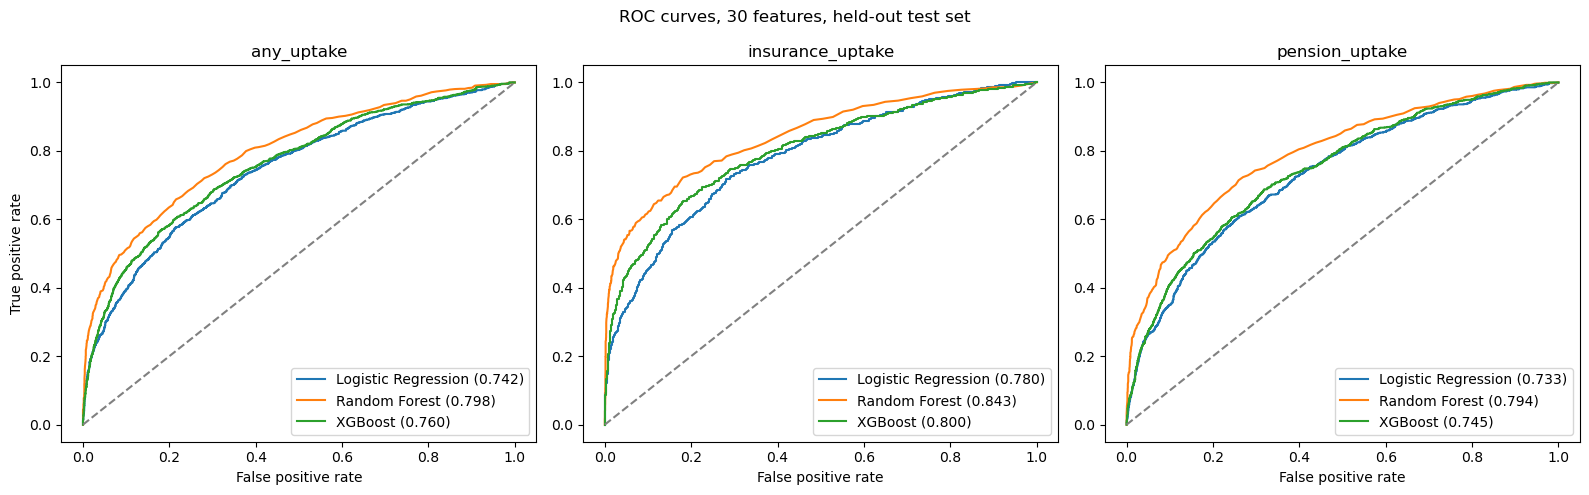

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, target in zip(axes, TARGETS):
    for model_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
        fpr, tpr, _ = roc_data[(target, "+ credit (30)", model_name)]
        auc = results_df.query("target == @target and features == '+ credit (30)' and model == @model_name")["AUC-ROC"].iloc[0]
        ax.plot(fpr, tpr, label=f"{model_name} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
    ax.set_title(target)
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.suptitle("ROC curves, 30 features, held-out test set")
plt.tight_layout()
plt.show()

In [20]:
# Best model per target (highest AUC-ROC across both feature sets).
best = results_df.loc[results_df.groupby("target")["AUC-ROC"].idxmax()].set_index("target").loc[TARGETS]
best

,features,model,AUC-ROC,PR-AUC,precision,recall,F1
target,,,,,,,
any_uptake,+ credit (30),Random Forest,0.798,0.694,0.810,0.389,0.525
insurance_uptake,+ credit (30),Random Forest,0.843,0.631,0.876,0.361,0.511
pension_uptake,+ credit (30),Random Forest,0.794,0.612,0.821,0.266,0.401


## Section 11 — Feature importance (SHAP)

Section 10 picked Random Forest by AUC-ROC, but there's a practical wrinkle: computing SHAP
values for this sklearn Random Forest is **very slow** (roughly 1 second per test row with this
scikit-learn/SHAP combination — fine for a one-off analysis, unusable for a live "individual
predictor" page that needs an answer in under a second). XGBoost's `TreeExplainer` is roughly
100x faster and the model file is ~5x smaller, which also matters for deploying on Streamlit
Community Cloud.

So from here on the notebook uses a **deeper XGBoost** (`max_depth=12`, `learning_rate=0.02`,
`n_estimators=600`) — tuned just enough in a quick side check to close most of the gap to Random
Forest's AUC. This is the same configuration used for the deployed Streamlit model, so the SHAP
story here matches what the dashboard shows. It is not the Section 10 XGBoost (`max_depth=4`,
`n_estimators=300`) — that one was deliberately left as a simple, comparable baseline for the
three-model shoot-out; this one is the production model.

In [21]:
from xgboost import XGBClassifier as XGBClassifier2
import shap

def make_shap_model():
    return XGBClassifier2(
        n_estimators=600, max_depth=12, learning_rate=0.02, subsample=0.7,
        colsample_bytree=0.3, min_child_weight=1, eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1,
    )

shap_models, shap_values_by_target = {}, {}
for target in TARGETS:
    m = make_shap_model().fit(X_train, train_processed[target])
    test_auc = roc_auc_score(test_processed[target], m.predict_proba(X_test)[:, 1])
    print(f"{target:18s} test AUC-ROC = {test_auc:.3f}  "
          f"(Section 10 best was {results_df.query('target == @target')['AUC-ROC'].max():.3f})")
    shap_models[target] = m
    shap_values_by_target[target] = shap.TreeExplainer(m).shap_values(X_test, check_additivity=False)

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


any_uptake         test AUC-ROC = 0.786  (Section 10 best was 0.798)


insurance_uptake   test AUC-ROC = 0.832  (Section 10 best was 0.843)


pension_uptake     test AUC-ROC = 0.776  (Section 10 best was 0.794)


### Group one-hot columns back onto the original 30 survey questions

Each `shap_values` column is one dummy (e.g. `education_Primary 1-3`); summing the dummies that
came from the same question gives one SHAP value per original predictor, which is what's
actually interpretable to a judge or a policymaker.

In [22]:
def feature_of_dummy(col):
    hits = [f for f in ALL_NAMES if col == f or col.startswith(f + "_")]
    return max(hits, key=len)  # longest match wins when one feature name prefixes another

feature_cols_enc = FEATURE_SETS["+ credit (30)"]
X_train, X_test = train_processed[feature_cols_enc], test_processed[feature_cols_enc]
dummy_to_feature = {c: feature_of_dummy(c) for c in feature_cols_enc}

def group_shap(sv, columns):
    df_sv = pd.DataFrame(sv, columns=columns)
    groups = pd.Series({c: dummy_to_feature[c] for c in columns})
    return df_sv.T.groupby(groups).sum().T[ALL_NAMES]

grouped_shap = {t: group_shap(shap_values_by_target[t], feature_cols_enc) for t in TARGETS}
grouped_shap["any_uptake"].head()

,age,sex,marital_status,education,ubudehe_category,owns_motor_vehicle,main_livelihood,urban_rural,time_to_bank,time_to_insurance_branch,time_to_sacco,used_mobile_money,saves_money,has_emergency_savings,aware_microinsurance,skipped_meal_frequency,housing_situation,household_size,agrees_insurance_never_pays,agrees_insurance_protects,agrees_savings_better,understands_insurance,aware_medical_insurance,aware_life_insurance,aware_third_party_insurance,borrowed_past_12m,borrowed_from_bank,borrowed_from_umurenge_sacco,borrowed_from_mfi_or_other_sacco,borrowed_via_mobile_money
0,0.060438,-0.093530,0.000669,-0.074336,-0.195371,-0.105644,0.121170,0.020382,-0.034586,-0.107775,-0.069676,0.073838,0.223310,-0.069811,-0.227894,-0.367583,0.112040,-0.038301,0.013636,-0.041506,-0.140563,-0.481196,0.157063,-0.000886,0.003311,0.066199,-0.021820,-0.079139,-0.042271,-0.011563
1,0.139392,0.019266,0.026970,-0.106864,-0.162040,-0.095511,-0.124262,-0.017662,-0.006935,-0.165711,0.022402,-0.063841,0.188655,0.298212,-0.143586,-0.120871,0.159408,-0.058193,0.002375,-0.072823,-0.099788,-0.316679,0.110470,-0.049519,-0.006453,0.000741,-0.019074,-0.066123,-0.040870,-0.015887
2,-0.033691,0.031594,0.036706,0.149740,0.029429,-0.093738,-0.165588,0.009709,0.010305,0.021588,-0.039518,-0.017782,0.104850,-0.067433,-0.187326,-0.174302,0.104046,0.025092,0.023600,-0.024474,-0.044339,-0.329598,0.059036,0.011804,-0.003599,0.111809,-0.021008,-0.060859,-0.041283,-0.007736
3,0.134541,0.013737,0.064827,-0.155955,0.021549,-0.062013,-0.146267,0.058190,0.027063,0.288823,0.069120,0.053616,-0.060891,-0.091043,-0.152468,0.122300,0.131438,-0.168536,-0.098481,-0.057941,-0.030131,0.095085,-0.073085,-0.118331,0.001914,0.167441,-0.019749,-0.036098,-0.026135,-0.004613
4,0.002740,0.004297,0.034330,0.140408,0.185781,-0.067704,-0.092441,-0.103201,-0.082961,-0.119261,0.113818,-0.023374,-0.060759,-0.094991,-0.186699,-0.007434,0.097328,-0.097729,0.083602,-0.022391,-0.062070,-0.330269,0.074403,-0.085562,-0.000316,-0.016586,-0.018917,-0.056955,-0.039923,-0.011536


### Global feature importance: mean(|SHAP|) per target

Bigger bars = the feature moves the model's prediction more, on average, across the test set —
in either direction. This is ranking by *influence*, not by "good" or "bad" for uptake.

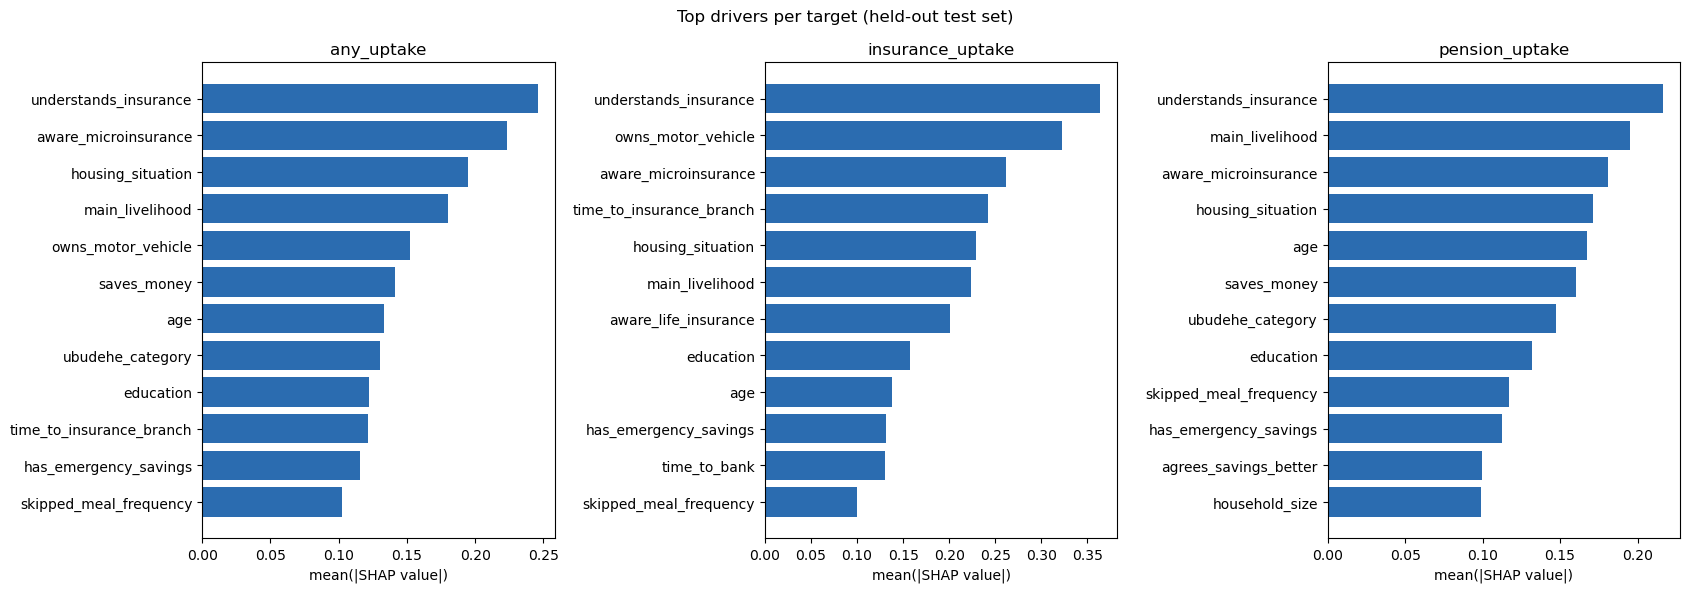

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
top_drivers = {}
for ax, target in zip(axes, TARGETS):
    importance = grouped_shap[target].abs().mean().sort_values(ascending=True)
    top_drivers[target] = importance.sort_values(ascending=False)
    ax.barh(importance.tail(12).index, importance.tail(12).values, color="#2b6cb0")
    ax.set_title(target)
    ax.set_xlabel("mean(|SHAP value|)")
plt.suptitle("Top drivers per target (held-out test set)")
plt.tight_layout()
plt.show()

In [24]:
print("Top 8 drivers per target:")
pd.DataFrame({t: top_drivers[t].head(8).index for t in TARGETS})

Top 8 drivers per target:


,any_uptake,insurance_uptake,pension_uptake
0,understands_insurance,understands_insurance,understands_insurance
1,aware_microinsurance,owns_motor_vehicle,main_livelihood
2,housing_situation,aware_microinsurance,aware_microinsurance
3,main_livelihood,time_to_insurance_branch,housing_situation
4,owns_motor_vehicle,housing_situation,age
5,saves_money,main_livelihood,saves_money
6,age,aware_life_insurance,ubudehe_category
7,ubudehe_category,education,education


### A worked example: one SHAP waterfall

Picking one test-set respondent and showing exactly how their 30 answers push the `any_uptake`
probability up or down from the model's average starting point. This is the same mechanic that
powers the Streamlit app's "Individual predictor" tab (Section 3 there) — there it runs on
whatever a user types into a form instead of a fixed test row.

In [25]:
row_i = test_processed[test_processed["any_uptake"] == 1].index[0]
contributions = grouped_shap["any_uptake"].iloc[row_i].sort_values()
# .expected_value can come back as a 1-element array rather than a scalar depending on
# the shap/xgboost version - np.ravel(...)[0] handles either case.
base_logit = np.ravel(shap.TreeExplainer(shap_models["any_uptake"]).expected_value)[0]
base_prob = 1 / (1 + np.exp(-base_logit))

print(f"Model's average starting probability: {base_prob:.1%}")
print(f"This respondent's actual predicted probability: "
      f"{shap_models['any_uptake'].predict_proba(X_test.iloc[[row_i]])[0, 1]:.1%}\n")
print("Top 6 factors pushing the prediction down (SHAP, log-odds):")
print(contributions.head(6).round(3))
print("\nTop 6 factors pushing the prediction up (SHAP, log-odds):")
print(contributions.tail(6).sort_values(ascending=False).round(3))

Model's average starting probability: 30.7%
This respondent's actual predicted probability: 31.0%

Top 6 factors pushing the prediction down (SHAP, log-odds):
household_size                -0.169
education                     -0.156
aware_microinsurance          -0.152
main_livelihood               -0.146
aware_life_insurance          -0.118
agrees_insurance_never_pays   -0.098
Name: 3, dtype: float32

Top 6 factors pushing the prediction up (SHAP, log-odds):
time_to_insurance_branch    0.289
borrowed_past_12m           0.167
age                         0.135
housing_situation           0.131
skipped_meal_frequency      0.122
understands_insurance       0.095
Name: 3, dtype: float32


**Caveats worth repeating before anyone quotes these as "causes":**

- SHAP explains *this model's* behaviour, not the real world — it is a correlate, not a proven
  causal driver.
- The awareness / understanding items (`understands_insurance`, `aware_*`) likely include some
  reverse causation: people who already hold a product are more likely to say they're aware of
  it or understand it.
- A handful of categories are tiny (e.g. Ubudehe "4th category" has 38 respondents) — their SHAP
  values are noisier than the headline bars suggest.

---
**Next (separate deliverable, not in this notebook):** a Streamlit dashboard — national picture,
segment explorer, individual predictor (SHAP waterfall, as above, on live user input) and
recommendations — built from these same models and the grouped SHAP values. See
`streamlit_app/`.